### Build A Basic Chatbot With Langgraph(GRAPH API)

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages


In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]



In [27]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-20b")

In [6]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x1144f4690>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1144f5090>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [7]:
llm = init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x1144f5d10>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1144f6710>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [8]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [9]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

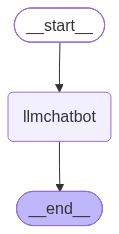

In [10]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [13]:
response=graph.invoke({"messages":"Hi"})
response

{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='ce5b8321-ddde-4553-b66a-8c4ea3e408dc'),
  AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "Hi". We need to respond with a greeting. Probably friendly.'}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 72, 'total_tokens': 107, 'completion_time': 0.038702486, 'completion_tokens_details': {'reasoning_tokens': 17}, 'prompt_time': 0.00341303, 'prompt_tokens_details': None, 'queue_time': 0.330602421, 'total_time': 0.042115516}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_34cb00738d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12e11-be5b-7841-9814-7fc41249d94e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 35, 'total_tokens': 107, 'output_token_details': {'reasoning': 17}})]}

In [14]:
response["messages"][-1].content

'Hello! How can I help you today?'

In [16]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I’m doing great—thanks for asking. How about you? What’s on your mind today?


### To maintain state across calls, add a checkpointer and use the same thread ID:

In [18]:
from langgraph.checkpoint.memory import InMemorySaver

graph = graph_builder.compile(
    checkpointer=InMemorySaver()
)

config = {"configurable": {"thread_id": "chat-1"}}

graph.invoke(
    {"messages": "My name is John."},
    config=config
)

response = graph.invoke(
    {"messages": "What is my name?"},
    config=config
)

response

{'messages': [HumanMessage(content='My name is John.', additional_kwargs={}, response_metadata={}, id='44b5aff2-0afb-4499-84af-16dabd13801a'),
  AIMessage(content='Nice to meet you, John! How can I help you today?', additional_kwargs={'reasoning_content': 'User says "My name is John." We need to respond. Likely ask how can I help. It\'s a greeting. Provide friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 53, 'prompt_tokens': 76, 'total_tokens': 129, 'completion_time': 0.055082714, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.003676768, 'prompt_tokens_details': None, 'queue_time': 0.043464222, 'total_time': 0.058759482}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_c5a89987dc', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12e91-eb36-77c0-b3a9-4975db624364-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 76, 'output_tokens'

In [19]:
print(response["messages"][-1].content)

Your name is John.


### Chatbot With Tool

In [28]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("What is langgraph")

{'query': 'What is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [29]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [30]:
tools=[tool,multiply]

In [31]:
llm_with_tool=llm.bind_tools(tools)

In [32]:
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x1144f5d10>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1144f6710>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted result

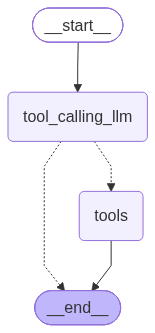

In [33]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))



In [35]:
response=graph.invoke({"messages":"What is the recent ai news"})
response

{'messages': [HumanMessage(content='What is the recent ai news', additional_kwargs={}, response_metadata={}, id='3bc2720d-db2c-4f3e-b81b-f7dcfeb668be'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks: "What is the recent ai news". We need to provide recent AI news. Since it\'s about current events, we should use the search tool to find recent AI news. Likely we need to search for "recent AI news" or "latest AI news" and provide a summary. Use tavily_search. We\'ll search for "latest AI news 2026 October" maybe. We\'ll need to provide citations. We\'ll produce a summary with multiple items. Let\'s search.', 'tool_calls': [{'id': 'fc_906f348b-cf25-4bf7-8569-50fe2c4ce3b9', 'function': {'arguments': '{"query":"latest AI news October 2026","search_depth":"advanced","time_range":"month","topic":"news"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 143, 'prompt_tokens': 348, 'total_tokens': 491, 'comp

In [36]:
response['messages'][-1].content

'{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://southfloridahospitalnews.com/2026/10/09/bcma-artificial-intelligence-conference-2026-october-17-2026", "title": "BCMA: Artificial Intelligence Conference 2026, October 17, 2026 - Florida Hospital News and Healthcare Report", "content": "This timely educational event will feature expert insights on emerging technologies, clinical applications, ethical considerations, and the future of AI in healthcare. Mark your calendar and plan to be part of this engaging discussion on one of medicine’s most transformative innovations.\\n\\nSponsorship opportunities are available for organizations interested in showcasing their commitment to advancing healthcare innovation. For sponsorship information, please contact Maria Virginia Urdaneta at murdaneta@bcma.com.\\n\\nYour participation supports our mission to educate and empower the medical community in Broward County, and

In [37]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_906f348b-cf25-4bf7-8569-50fe2c4ce3b9)
 Call ID: fc_906f348b-cf25-4bf7-8569-50fe2c4ce3b9
  Args:
    query: latest AI news October 2026
    search_depth: advanced
    time_range: month
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news October 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://southfloridahospitalnews.com/2026/10/09/bcma-artificial-intelligence-conference-2026-october-17-2026", "title": "BCMA: Artificial Intelligence Conference 2026, October 17, 2026 - Florida Hospital News and Healthcare Report", "content": "This timely educational event will feature expert insights on emerging technologies, clinical applications, et

In [41]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
response


{'messages': [HumanMessage(content='What is 5 multiplied by 2', additional_kwargs={}, response_metadata={}, id='63b1eca4-4ca1-4044-afd6-92a0e6003d0f'),
  AIMessage(content='5 multiplied by 2 equals **10**.', additional_kwargs={'reasoning_content': "We need to compute 5 * 2. That's 10. Probably no tool needed."}, response_metadata={'token_usage': {'completion_tokens': 39, 'prompt_tokens': 350, 'total_tokens': 389, 'completion_time': 0.059782972, 'completion_tokens_details': {'reasoning_tokens': 20}, 'prompt_time': 0.026498476, 'prompt_tokens_details': None, 'queue_time': 0.30361932, 'total_time': 0.086281448}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_9340e7d14d', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12ed4-689a-7bc3-b86d-15ba22aa8fe7-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 350, 'output_tokens': 39, 'total_tokens': 389, 'output_token_details': {'reasoning': 2

In [42]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================

5 multiplied by 2 equals **10**.


In [43]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_48fc5826-d6ac-4273-b546-14966618492f)
 Call ID: fc_48fc5826-d6ac-4273-b546-14966618492f
  Args:
    query: recent AI news 2026 October
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.enterprisetimes.co.uk/2026/10/12/security-and-ai-news-from-the-week-beginning-5-october-2026", "title": "Security and AI news from the week beginning 5 October 2026 -", "content": "India has announced a consultation on its highly anticipated AI regulation roadmap. It will focus on deepfakes and safety, and a consultat

### ReAct Agent Architecture

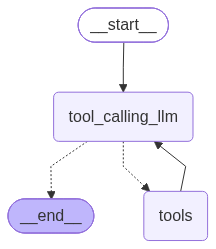

In [44]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [45]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_1e867c4e-bb92-42c5-839f-d995432fd894)
 Call ID: fc_1e867c4e-bb92-42c5-839f-d995432fd894
  Args:
    query: recent AI news 2026 October
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news 2026 October", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.enterprisetimes.co.uk/2026/10/12/security-and-ai-news-from-the-week-beginning-5-october-2026", "title": "Security and AI news from the week beginning 5 October 2026 -", "content": "India has announced a consultation on its highly anticipated AI regulation roadmap. It will focus on deepfakes and safety, and a consultat

## Adding Memory In Agentic Graph

In [46]:
response=graph.invoke({"messages":"Hello my name is KRish"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is KRish
================================== Ai Message ==================================

Hello KRish! How can I help you today?


In [47]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I’m not sure—could you tell me your name?


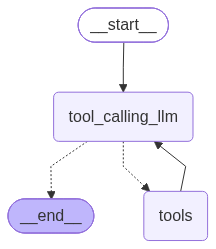

In [48]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [49]:
config={"configurable":{"thread_id":"1"}}

response=graph.invoke({"messages":"Hi my name is Krish"},config=config)

response



{'messages': [HumanMessage(content='Hi my name is Krish', additional_kwargs={}, response_metadata={}, id='485d3e71-ee7a-4a8d-a48e-f7d4e342577e'),
  AIMessage(content='Hello Krish! 👋 How can I help you today?', additional_kwargs={'reasoning_content': 'User says: "Hi my name is Krish". We should respond politely. No tool usage.'}, response_metadata={'token_usage': {'completion_tokens': 43, 'prompt_tokens': 348, 'total_tokens': 391, 'completion_time': 0.046234488, 'completion_tokens_details': {'reasoning_tokens': 21}, 'prompt_time': 0.022218633, 'prompt_tokens_details': None, 'queue_time': 0.079423937, 'total_time': 0.068453121}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_c5a89987dc', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12ef1-8969-79e2-9e98-a1f9c898135b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 348, 'output_tokens': 43, 'total_tokens': 391, 'output_token_details

In [50]:
response['messages'][-1].content

'Hello Krish! 👋 How can I help you today?'

In [51]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Krish. If you’d like to share anything else or ask a question, just let me know!


In [53]:
response=graph.invoke({"messages":"Hey do you remember my name"},config=config)

print(response['messages'][-1].content)

Yes, your name is Krish. If there’s anything else you’d like to talk about or ask, just let me know!


In [54]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [55]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

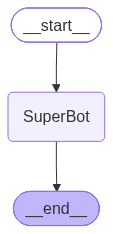

In [56]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [57]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Krish And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='d4eaee17-c130-45a9-be5f-5d5850913a70'),
  AIMessage(content='Hey Krish! 👋🏼 Great to meet someone who loves cricket. Is there anything specific you’d like to chat about—maybe your favorite team, player, or a recent match? Or perhaps you’re looking for stats, trivia, or even a fun cricket quiz? Let me know what you’re in the mood for!', additional_kwargs={'reasoning_content': 'We need to respond. The user says: "Hi,My name is Krish And I like cricket". We should greet them, ask how we can help, maybe talk about cricket. The user hasn\'t asked a question. So we can respond with friendly greeting. Also we can ask if they want to talk about cricket or something else.'}, response_metadata={'token_usage': {'completion_tokens': 144, 'prompt_tokens': 82, 'total_tokens': 226, 'completion_time': 0.155626427, 'completion_tokens_details': {'reasoning_tokens': 69}, 'prompt_tim

### Streaming 
Methods: .stream() and astream()

- These methods are sync and async methods for streaming back results.

Additional parameters in streaming modes for graph state

- **values** : This streams the full state of the graph after each node is called.
- **updates** : This streams updates to the state of the graph after each node is called.

In [58]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hello Krish! 👋 It’s great to meet a fellow cricket fan. Which team or player do you follow the most? Or is there a particular match or era you love? Feel free to share—happy to chat about cricket or anything else that interests you!', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says "Hi, My name is Krish And I like cricket". We can greet them. Possibly ask about cricket. There\'s no request, just a greeting. So we respond friendly, maybe ask what teams or players they like.'}, response_metadata={'token_usage': {'completion_tokens': 120, 'prompt_tokens': 82, 'total_tokens': 202, 'completion_time': 0.165769577, 'completion_tokens_details': {'reasoning_tokens': 57}, 'prompt_time': 0.004622089, 'prompt_tokens_details': None, 'queue_time': 0.320326958, 'total_time': 0.170391666}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_c9afb2bdb4', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'l

In [59]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='8ea9b2f7-493d-4a02-8d44-d4611b71cdd3'), AIMessage(content='Hello Krish! 👋 It’s great to meet a fellow cricket fan. Which team or player do you follow the most? Or is there a particular match or era you love? Feel free to share—happy to chat about cricket or anything else that interests you!', additional_kwargs={'reasoning_content': 'We need to respond as ChatGPT. The user says "Hi, My name is Krish And I like cricket". We can greet them. Possibly ask about cricket. There\'s no request, just a greeting. So we respond friendly, maybe ask what teams or players they like.'}, response_metadata={'token_usage': {'completion_tokens': 120, 'prompt_tokens': 82, 'total_tokens': 202, 'completion_time': 0.165769577, 'completion_tokens_details': {'reasoning_tokens': 57}, 'prompt_time': 0.004622089, 'prompt_tokens_details': None, 'queue_time': 0.320326958, 'total_time': 0.17039

In [60]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hello Krish! That’s great to hear—cricket is such an exciting sport. Which team or player do you follow the most? And are you a fan of any particular format, like Test, ODI, or T20?', additional_kwargs={'reasoning_content': 'User says "Hi, My name is Krish And I like cricket". They introduced themselves. They likely want a response. Should respond politely, maybe ask about cricket. Should not mention policy. Should be friendly.'}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 82, 'total_tokens': 182, 'completion_time': 0.121992678, 'completion_tokens_details': {'reasoning_tokens': 44}, 'prompt_time': 0.00401218, 'prompt_tokens_details': None, 'queue_time': 0.331973586, 'total_time': 0.126004858}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_99996fee8e', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a12ef9-c2b4-7813-a3fe-697553

In [61]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='d5b92b59-03b0-49cb-8432-09975a2dd556'), AIMessage(content='Hello Krish! That’s great to hear—cricket is such an exciting sport. Which team or player do you follow the most? And are you a fan of any particular format, like Test, ODI, or T20?', additional_kwargs={'reasoning_content': 'User says "Hi, My name is Krish And I like cricket". They introduced themselves. They likely want a response. Should respond politely, maybe ask about cricket. Should not mention policy. Should be friendly.'}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 82, 'total_tokens': 182, 'completion_time': 0.121992678, 'completion_tokens_details': {'reasoning_tokens': 44}, 'prompt_time': 0.00401218, 'prompt_tokens_details': None, 'queue_time': 0.331973586, 'total_time': 0.126004858}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_99996fee8e', 'se

In [62]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a12efa-76cf-7040-a808-e431049039b6', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='8ddd657a-6cc7-41cd-9693-df6bd750dcf1')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a12efa-76d3-7d00-b7d8-8670af477822', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:98c0712a-2cd7-e3f8-8bd0-d6aaa5306f9a'}, 'parent_ids': ['01a12efa-76cf-7040-a808-e431049039b6']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':